In [21]:
# Versão para Atividade 4
import geopandas as gpd
import numpy as np
import random
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

from shapely.geometry import Polygon

import geopandas as gpd
import matplotlib.pyplot as plt
import contextily as ctx

import numpy as np
from matplotlib import pyplot as plt
from itertools import product

# Importa e reprojeta os arquivos
AREAS_INTERESSE = gpd.read_file('PEmSE/area_interesse.shp').to_crs('EPSG:3857')
PASSAGENS_SAR = gpd.read_file('PEmSE/passagens_SAR.shp').to_crs('EPSG:3857')

# Calcula a área em km2 segundo a projeção definida
AREAS_INTERESSE['area_km2'] = AREAS_INTERESSE.to_crs('EPSG:3857').geometry.area / 1000000
PASSAGENS_SAR['area_km2'] = PASSAGENS_SAR.to_crs('EPSG:3857').geometry.area / 1000000

WEIGHTS = [1, 1.5, 0.5] # AC, NP e SO

VERBOSE_OUTPUT = True
VERBOSE_EVALUATION = True

print(f"Number of passages: {len(PASSAGENS_SAR)}")

print(AREAS_INTERESSE)

print(AREAS_INTERESSE.sum(numeric_only=True))

Number of passages: 702
   DN  area                                           geometry       area_km2
0   1     3  POLYGON ((-6064650.101 -312930.486, -6052850.3...    3738.925071
1   1     4  POLYGON ((-5351101.095 -365993.039, -5336852.3...   28187.026492
2   1     7  POLYGON ((-5973591.897 -677640.649, -5964909.0...    7564.353656
3   1     8  POLYGON ((-6581833.982 -675625.641, -6572483.2...   39069.397812
4   1    11  POLYGON ((-6355412.972 -1060595.143, -6352296....    7764.852837
5   1    12  POLYGON ((-7080761.696 -770407.192, -7076976.8...  122662.452378
6   1    13  POLYGON ((-6066876.463 -1293839.277, -6064650....    7037.422047
DN               7.000000
area            58.000000
area_km2    216024.430292
dtype: float64


In [12]:
# indexes = np.array(PASSAGENS_SAR.index.tolist())
# # gerar máscara binária
# rng = np.random.default_rng()
# mascara_int = rng.integers(0, 2, size = len(PASSAGENS_SAR), dtype = int)
# mascara_int

def evaluate_passagens_min(mask_bin):
    selected_passagens = PASSAGENS_SAR.iloc[mask_bin.astype(bool)]
    # Penalidade alta se nenhuma passagem for selecionada
    if selected_passagens.empty:
        return 1e6

    intersecao = gpd.overlay(AREAS_INTERESSE, selected_passagens, how='intersection')
    # Se as passagens selecionadas não tocarem as áreas de interesse
    if intersecao.empty:
        return 1e6

    # Calcula área em km² para as faixas selecionadas
    area_intersections = intersecao.copy()
    area_intersections['area_km2'] = area_intersections.geometry.area / 1e6
    area_intersection_sum = area_intersections['area_km2'].sum(numeric_only=True)

    # Área dissolvida sem sobreposição
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1e6

    # Sobreposição normalizada (com proteção contra divisão por zero)
    over_areas = area_intersection_sum + area_uniao
    overlap = 0.0
    if over_areas > 0:
      overlap = (area_intersection_sum - area_uniao) / over_areas

    area_total = AREAS_INTERESSE['area_km2'].sum()
    area_covered = area_uniao / area_total
    passagens = len(selected_passagens) / len(PASSAGENS_SAR)

    w1, w2, w3 = WEIGHTS

    # Minimizar a área não coberta, a quantidade de passagens e a sobreposição
    score = (w1 * (1.0 - area_covered)) + (w2 * passagens) + (w3 * overlap)

    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )

    return score

def evaluate_passagens_max(mask_bin):
    selected_passagens = PASSAGENS_SAR.iloc[mask_bin.astype(bool)]
    # Retorna zero se nenhuma passagem foi selecionada
    if selected_passagens.empty:
        return 0

    # Calcula a interseção das passagens com a área de interesse
    intersecao = gpd.overlay(
        AREAS_INTERESSE,
        selected_passagens,
        how='intersection'
    )

    # Calcula a soma das áreas de interseção
    area_intersections = intersecao.geometry.area.sum() / 1000000

    # Calcula a área total coberta, sem contar as sobreposições
    uniao = intersecao.geometry.union_all()
    area_uniao = uniao.area / 1000000

    # Calcula as métricas da solução
    overlap = (area_intersections - area_uniao) / (area_intersections + area_uniao)
    area_covered = area_uniao / AREAS_INTERESSE['area_km2'].sum()
    passages = len(selected_passagens) / len(PASSAGENS_SAR)

    # Define os pesos da função objetivo
    w1, w2, w3 = WEIGHTS

    # Calcula o score da solução
    score = w1 * area_covered - w2 * passages - w3 * overlap

    if VERBOSE_EVALUATION:
        print(
            f"Área coberta (AC): {area_covered:.6f} |",
            f"Número de passagens (NP): {len(selected_passagens)} |",
            f"Sobreposição (SO): {overlap:.6f} |",
            f"Score (Loss): {score:.6f}"
        )

    return score

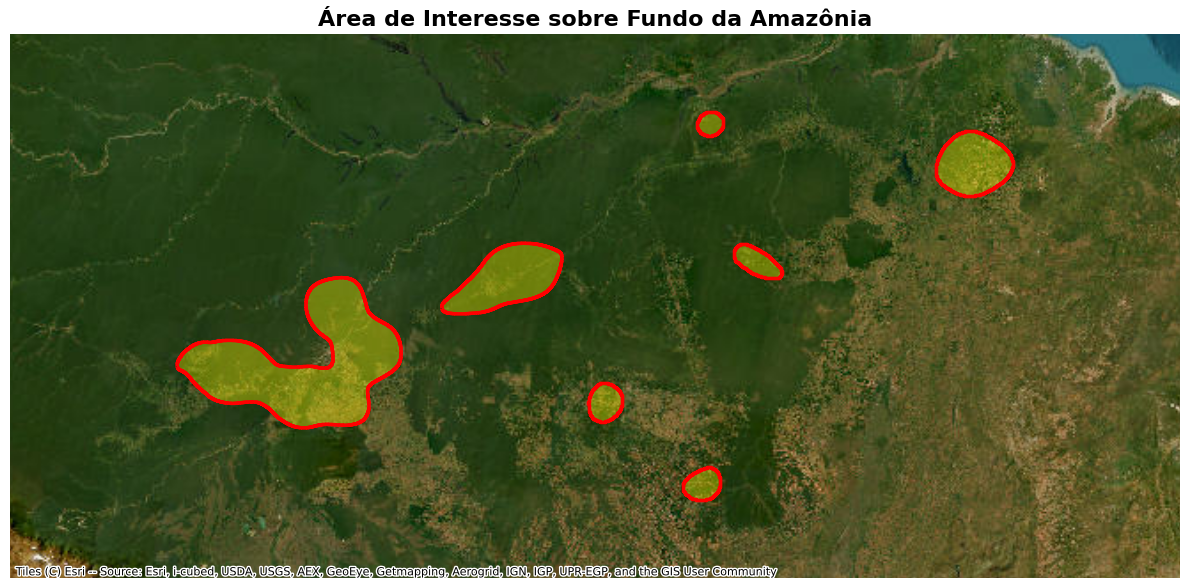

In [6]:
# Reprojetar para o sistema usado pelo mapa-base
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# Plotar a área de interesse preenchida
area_plot.plot(
    ax=ax,
    facecolor='yellow',
    edgecolor='red',
    alpha=0.35,
    linewidth=2.5,
    zorder=2
)

# Opcional: desenhar também só o contorno por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=2.5,
    zorder=3
)

ax.set_title('Área de Interesse sobre Fundo da Amazônia', fontsize=16, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('area_interesse_amazonia_fundo.png', dpi=300, bbox_inches='tight')
plt.show()

In [33]:
def fitness_default(fob_value):
    """
    Função de aptidão para minimização.
    Garante que valores menores de fob tenham maior fitness na roleta.
    """
    if fob_value >= 0:
        return 1.0 / (1.0 + fob_value)
    return 1.0 + abs(fob_value)

class Individual:
    def __init__(self, x_bin, fob, fitness_func):
        self._fob = fob
        self._fitness = fitness_func
        self.x_bin = np.asarray(x_bin, dtype=int)

        # A própria fob avalia diretamente a máscara binária
        self.fob = float(fob(self.x_bin))
        self.fitness = float(fitness_func(self.fob))


class Population:
    def __init__(self, pop_size, crom_size, fob, fitness_func, p_init=0.5):
        self.pop_size = pop_size
        self.individuals = []
        rng = np.random.default_rng()
        for _ in range(pop_size):
            # Vetor binário de tamanho N correspondente às geometrias
            x_bin = (rng.random(size=crom_size) < p_init).astype(int)
            self.individuals.append(Individual(x_bin, fob, fitness_func))


class Roulette:
    def __init__(self, population):
        self.roulette_range = []
        total_fit = sum(ind.fitness for ind in population.individuals)

        # Prevenção contra divisão por zero
        if total_fit == 0:
            total_fit = 1e-9

        cumulative = 0.0
        for individual in population.individuals:
            cumulative += individual.fitness / total_fit
            self.roulette_range.append(cumulative)
        self.roulette_range[-1] = 1.0

    def spin(self):
        r = np.random.uniform(0, 1)
        for i, v in enumerate(self.roulette_range):
            if v > r:
                return i
        return len(self.roulette_range) - 1

def tournament_selection(individuals, method="min", k=3):
    candidates = np.random.choice(individuals, size=k, replace=False)
    comparator = min if method == "min" else max
    return comparator(candidates, key=lambda ind: ind.fob)

def ranking_selection(individuals, method="min"):
    n = len(individuals)
    # Ordena do pior (rank 1) para o melhor (rank N)
    # Se min: maiores fobs são os piores; se max: menores fobs são os piores
    reverse_order = True if method == "min" else False
    sorted_inds = sorted(individuals, key=lambda ind: ind.fob, reverse=reverse_order)

    # Probabilidades lineares: rank i tem peso i
    ranks = np.arange(1, n + 1)
    probs = ranks / ranks.sum()

    idx = np.random.choice(n, p=probs)
    return sorted_inds[idx]

def mutation(individual, pm):
    rng = np.random.default_rng()
    x_bin_mut = []
    for bit in individual.x_bin:
        prob = rng.random()
        if prob > pm:
            x_bin_mut.append(bit)
        else:
            x_bin_mut.append(bit ^ 1)
    return Individual(x_bin_mut, individual._fob, individual._fitness)

def cross(parent_1, parent_2):
    pc = int(len(parent_1.x_bin) / 2)
    child_1_bits = np.concatenate([parent_1.x_bin[:pc], parent_2.x_bin[pc:]])
    child_2_bits = np.concatenate([parent_2.x_bin[:pc], parent_1.x_bin[pc:]])

    child_1 = Individual(child_1_bits, parent_1._fob, parent_1._fitness)
    child_2 = Individual(child_2_bits, parent_1._fob, parent_1._fitness)
    return child_1, child_2

class GeoGeneticAlgorithm:
    def __init__(self):
        self.population = None
        self.best = None
        self.best_mask = None
        self.best_f_history = []
        self.fob = None
        self.method = "min"
        self.selection_method = "roulette"

    def _select_parent(self, roulette, selection_method, tournament_size):
        """Helper interno para retornar um indivíduo de acordo com o operador escolhido."""
        if selection_method == "roulette":
            idx = roulette.spin()
            return self.population.individuals[idx]
        elif selection_method == "tournament":
            return tournament_selection(
                self.population.individuals,
                method=self.method,
                k=tournament_size,
            )
        elif selection_method == "ranking":
            return ranking_selection(
                self.population.individuals,
                method=self.method,
            )

    def run(
        self,
        fob,
        n_geometries,
        pop_size=100,
        n_generations=50,
        pm=0.01,
        p_init=0.5,
        fitness_func=None,
        elitism=True,
        seed=None,
        method="min",                  # 'min' ou 'max'
        selection_method="tournament", # 'roulette', 'tournament' ou 'ranking'
        tournament_size=3,             # Tamanho 'k' do torneio (se selection_method='tournament')
    ):
        if method not in ("min", "max"):
            raise ValueError("O parâmetro 'method' deve ser 'min' ou 'max'.")

        valid_selections = ("roulette", "tournament", "ranking")
        if selection_method not in valid_selections:
            raise ValueError(f"O parâmetro 'selection_method' deve ser um de: {valid_selections}")

        self.method = method
        self.selection_method = selection_method
        best_selector = min if method == "min" else max

        # Fitness padrão caso use Roleta e nenhuma função customizada seja passada
        if fitness_func is None:
            if method == "min":
                fitness_func = lambda score: 1.0 / (1.0 + max(score, 0))
            else:
                fitness_func = lambda score: max(score, 0.0) + 1e-6

        if seed is not None:
            np.random.seed(seed)

        self.fob = fob
        self.best_f_history = []

        self.population = Population(
            pop_size, n_geometries, fob, fitness_func, p_init=p_init
        )

        for generation in range(n_generations):
            current_best = best_selector(
                self.population.individuals, key=lambda ind: ind.fob
            )
            self.best_f_history.append(current_best.fob)

            # Instancia a roleta apenas se ela for o método escolhido
            roulette = Roulette(self.population) if selection_method == "roulette" else None
            new_individuals = []

            # Elitismo: preserva a melhor solução atual
            if elitism:
                new_individuals.append(current_best)

            while len(new_individuals) < pop_size:
                # Seleção flexível dos progenitores
                parent_1 = self._select_parent(roulette, selection_method, tournament_size)
                parent_2 = self._select_parent(roulette, selection_method, tournament_size)

                child_1, child_2 = cross(parent_1, parent_2)

                child_1 = mutation(child_1, pm)
                child_2 = mutation(child_2, pm)

                new_individuals.append(child_1)
                if len(new_individuals) < pop_size:
                    new_individuals.append(child_2)

            if VERBOSE_OUTPUT:
                best = best_selector(new_individuals, key=lambda ind: ind.fob)
                best_mask = best.x_bin.astype(bool)
                best_score = best.fob

                print(
                    "================>",
                    f"Geração {generation + 1}: ",
                    f"Melhor score ({self.method} | {self.selection_method}): {best_score:.4f} |",
                    f"Geometrias selecionadas: {best_mask.sum()}",
                )

            self.population.individuals = new_individuals

        # Melhor indivíduo final
        self.best = best_selector(
            self.population.individuals, key=lambda ind: ind.fob
        )
        self.best_mask = self.best.x_bin.astype(bool)

        return self.best_mask, self.best.fob

    def plot_convergence(self):
        """Plota a curva de convergência do score."""
        if not self.best_f_history:
            raise ValueError("Execute o método 'run' antes de gerar o gráfico.")

        fig, ax = plt.subplots(figsize=(9, 4))

        geracoes = range(1, len(self.best_f_history) + 1)
        ax.plot(
            geracoes,
            self.best_f_history,
            marker="o",
            markersize=3,
            color="tab:blue",
        )

        ax.xaxis.set_major_locator(MaxNLocator(integer=True))

        ax.set_xlabel("Geração")
        ax.set_ylabel("Melhor Score f(x)")
        ax.set_title(
            f"Convergência do AG ({self.method.upper()} | Seleção: {self.selection_method.capitalize()})"
        )
        ax.grid(True, linestyle="--", alpha=0.6)

        plt.tight_layout()
        plt.show()

================> Geração 1:  Melhor score (min | tournament): 1.0232 | Geometrias selecionadas: 313
================> Geração 2:  Melhor score (min | tournament): 1.0232 | Geometrias selecionadas: 313
================> Geração 3:  Melhor score (min | tournament): 1.0232 | Geometrias selecionadas: 313
================> Geração 4:  Melhor score (min | tournament): 1.0159 | Geometrias selecionadas: 311
================> Geração 5:  Melhor score (min | tournament): 1.0148 | Geometrias selecionadas: 309

Melhor score obtido: 1.0148
Geometrias selecionadas: 309


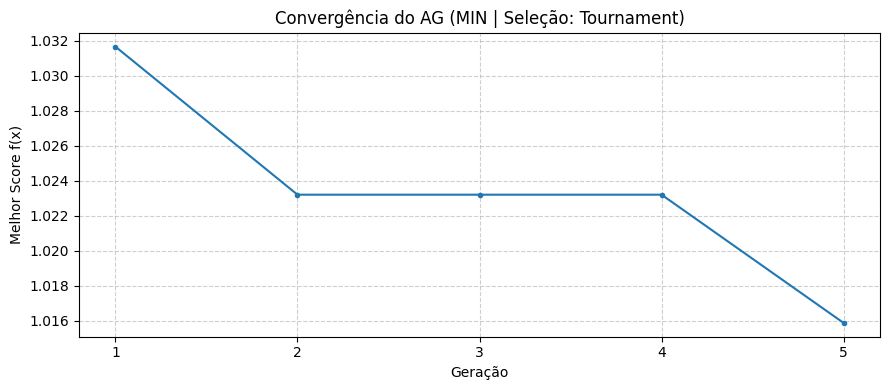

In [24]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = True

ga = GeoGeneticAlgorithm()
best_mask, best_score = ga.run(
    fob              = evaluate_passagens_min,
    n_geometries     = len(PASSAGENS_SAR),
    pop_size         = 10,
    n_generations    = 5,
    pm               = 0.02,
    p_init           = 0.5,
    elitism          = True,
    seed             = 46,
    method           = "min",
    selection_method = "tournament", # 'roulette', 'tournament' ou 'ranking'
    tournament_size  = 3,             # Tamanho 'k' do torneio (se selection_method='tournament')
)

print(f"\nMelhor score obtido: {best_score:.4f}")
print(f"Geometrias selecionadas: {best_mask.sum()}")

# Filtrando o GeoDataFrame original com a melhor máscara encontrada
gdf_otimizado_min = PASSAGENS_SAR.iloc[best_mask]

# Plot da convergência
ga.plot_convergence()

================> Geração 1:  Melhor score (max | tournament): -0.0430 | Geometrias selecionadas: 321
================> Geração 2:  Melhor score (max | tournament): -0.0293 | Geometrias selecionadas: 315
================> Geração 3:  Melhor score (max | tournament): -0.0293 | Geometrias selecionadas: 315
================> Geração 4:  Melhor score (max | tournament): -0.0159 | Geometrias selecionadas: 306
================> Geração 5:  Melhor score (max | tournament): -0.0137 | Geometrias selecionadas: 308

Melhor score obtido: -0.0137
Geometrias selecionadas: 308


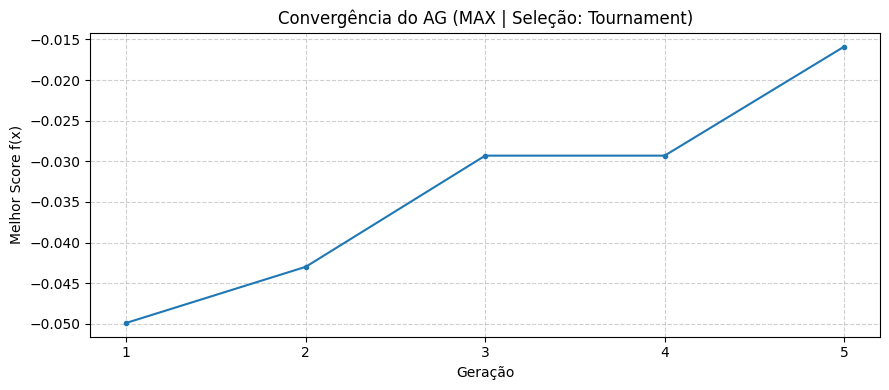

In [26]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = True

ga = GeoGeneticAlgorithm()
best_mask, best_score = ga.run(
    fob              = evaluate_passagens_max,
    n_geometries     = len(PASSAGENS_SAR),
    pop_size         = 10,
    n_generations    = 5,
    pm               = 0.02,
    p_init           = 0.5,
    elitism          = True,
    seed             = 46,
    method           = "max",
    selection_method = "tournament", # 'roulette', 'tournament' ou 'ranking'
    tournament_size  = 3,             # Tamanho 'k' do torneio (se selection_method='tournament')
)

print(f"\nMelhor score obtido: {best_score:.4f}")
print(f"Geometrias selecionadas: {best_mask.sum()}")

# Filtrando o GeoDataFrame original com a melhor máscara encontrada
gdf_otimizado_max = PASSAGENS_SAR.iloc[best_mask]

# Plot da convergência
ga.plot_convergence()

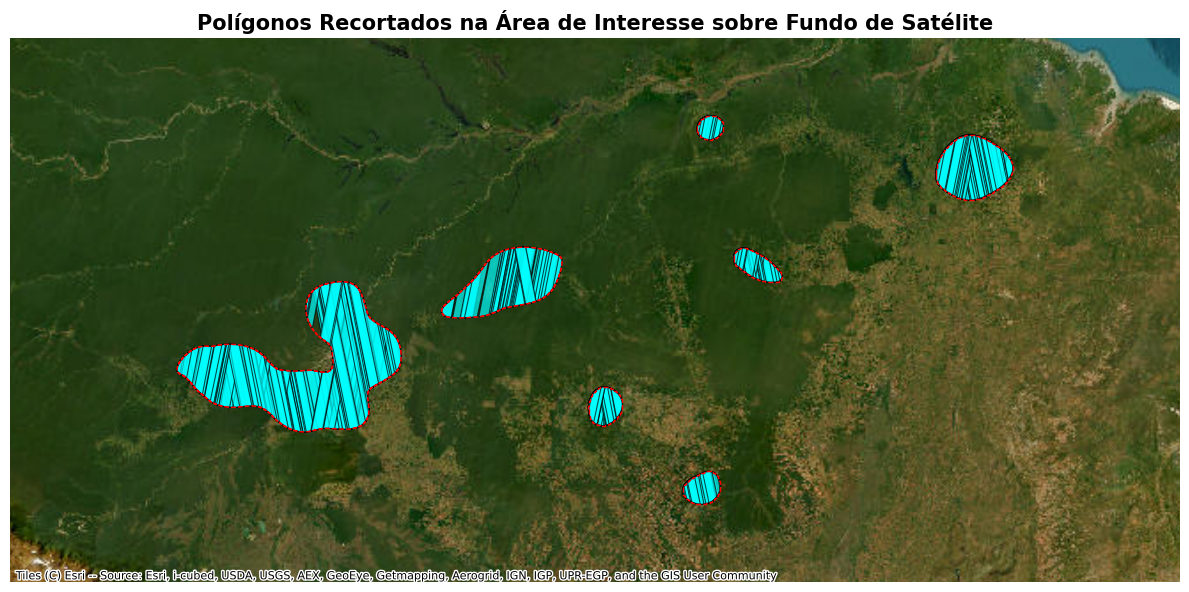

In [14]:
# 2. Recortar o gdf_final usando a geometria da área de interesse
gdf_recortado = gdf_otimizado_max.clip(AREAS_INTERESSE)

# 3. Reprojetar ambos para EPSG:3857 (usado pelo mapa-base do contextily)
area_plot = AREAS_INTERESSE.to_crs(epsg=3857)
gdf_recortado_plot = gdf_recortado.to_crs(epsg=3857)

# Criar figura
fig, ax = plt.subplots(figsize=(12, 10))

# Limites da área de interesse
xmin, ymin, xmax, ymax = area_plot.total_bounds

# Adiciona uma margem ao redor da área
dx = xmax - xmin
dy = ymax - ymin

margem_x = dx * 0.20
margem_y = dy * 0.20

ax.set_xlim(xmin - margem_x, xmax + margem_x)
ax.set_ylim(ymin - margem_y, ymax + margem_y)

# Adiciona o fundo de satélite
ctx.add_basemap(
    ax,
    source=ctx.providers.Esri.WorldImagery,
    crs=area_plot.crs
)

# 4. Plotar o gdf final recortado
gdf_recortado_plot.plot(
    ax=ax,
    color='cyan',         # ou use 'column=nome_coluna' caso tenha classes
    alpha=0.7,
    edgecolor='black',
    linewidth=0.8,
    zorder=2,
    label='Polígonos Selecionados'
)

# 5. Desenhar o contorno da área de interesse por cima
area_plot.boundary.plot(
    ax=ax,
    color='red',
    linewidth=1,
    linestyle='--',
    zorder=3,
    label='Área de Interesse'
)

ax.set_title('Polígonos Recortados na Área de Interesse sobre Fundo de Satélite', fontsize=15, fontweight='bold')
ax.set_axis_off()

plt.tight_layout()
plt.savefig('gdf_recortado_amazonia.png', dpi=300, bbox_inches='tight')
plt.show()

In [32]:
# Grid Search: busca exaustiva que testa todas as combinações possíveis de hiperparâmetros


# Define os valores dos hiperparâmetros que serão testados
parametros = {
    'tamanho_populacao': [30, 50],
    'numero_geracoes': [50, 80],
    'taxa_mutacao': [0.01, 0.02, 0.05],
    'elitism': [True, False],
    'selection_method': ["roulette", "tournament", "ranking"]
}

# Gera todas as combinações possíveis de hiperparâmetros
combinacoes = list(product(
    parametros['tamanho_populacao'],
    parametros['numero_geracoes'],
    parametros['taxa_mutacao'],
    parametros['elitism'],
    parametros['selection_method']
))

# Exibe a quantidade de combinações geradas
print(f"Total de combinações: {len(combinacoes)}")

Total de combinações: 72


In [34]:
combinacoes[0:1]

[(30, 50, 0.01, True, 'roulette')]

In [35]:
VERBOSE_EVALUATION = False
VERBOSE_OUTPUT = False

resultados_grid = []

for tamanho_populacao, numero_geracoes, taxa_mutacao, elitism, selection_method in combinacoes[0:1]:
    print(
        f"\nTestando: pop = {tamanho_populacao} | "
        f"gerações = {numero_geracoes} | "
        f"mutação = {taxa_mutacao} | "
        f"elitismo = {elitism} | "
        f"seleção = {selection_method}"
    )

    # Executa o algoritmo genético com os parâmetros da iteração atual
    ga = GeoGeneticAlgorithm()
    best_mask, best_score = ga.run(
        fob              = evaluate_passagens_max,
        n_geometries     = len(PASSAGENS_SAR),
        pop_size         = tamanho_populacao,
        n_generations    = numero_geracoes,
        pm               = taxa_mutacao,
        p_init           = 0.5,
        elitism          = elitism,
        seed             = 46,
        method           = "max",
        selection_method = selection_method, 
        tournament_size  = 3
    )
    
    # Cópia do histórico da rodada
    historico = list(ga.best_f_history)

    # Armazena os resultados da execução
    resultados_grid.append({
        'tamanho_populacao': tamanho_populacao,
        'numero_geracoes': numero_geracoes,
        'taxa_mutacao': taxa_mutacao,
        'elitism': elitism,
        'selection_method': selection_method,
        'melhor_score': melhor_score,
        'passagens_selecionadas': int(np.sum(melhor_individuo)),
        'melhor_mascara': melhor_individuo,
        'historico_convergencia': historico
    })

# 3. Consolidação e visualização dos resultados
df_resultados = pd.DataFrame(resultados_grid)

# Ordena pelo melhor resultado (ascendente para minimização, descendente para maximização)
df_resultados = df_resultados.sort_values(by='melhor_score', ascending=True).reset_index(drop=True)

print("\n--- TOP 5 MELHORES CONFIGURAÇÕES ---")
colunas_exibicao = [
    'selection_method', 'tamanho_populacao', 'numero_geracoes', 
    'taxa_mutacao', 'elitism', 'melhor_score', 'passagens_selecionadas'
]
print(df_resultados[colunas_exibicao].head())


Testando: pop=30 | gerações=50 | mutação=0.01 | elitismo=True | seleção=roulette


KeyboardInterrupt: 